In [44]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np
import re

In [30]:
# each point is length, width, type (0, 1)

data = [[3,   1.5, 1],
        [2,   1,   0],
        [4,   1.5, 1],
        [3,   1,   0],
        [3.5, .5,  1],
        [2,   .5,  0],
        [5.5,  1,  1],
        [1,    1,  0]]

mystery_flower = [5.5, 1]

In [47]:
# Sentence data: [sentence, sentiment_label (0 = negative, 1 = positive)]
sentence_data = [
    ["I absolutely love this product and would buy it again", 1],
    ["The experience was frustrating and disappointing", 0],
    ["This was an outstanding purchase with excellent quality", 1],
    ["The service was poor and the item arrived damaged", 0],
    ["Very satisfied with the fast delivery and great design", 1],
    ["I regret buying this because it is low quality", 0],
    ["My order was perfect and I am very pleased", 1],
    ["This item is awful and not worth the price", 0]
]

mystery_sentence = "This product feels fantastic and beautifully made"

In [ ]:
# Build vocabulary from all sentences
all_words = []
for sentence, label in sentence_data:
    words = re.findall(r"\b[\w']+\b", sentence.lower())
    all_words.extend(words)

vocab = sorted(set(all_words))
word_to_index = {word: idx for idx, word in enumerate(vocab)}


In [ ]:
# One-hot encode every sentence
onehot_sentences = []

for sentence, label in sentence_data:
    words = re.findall(r"\b[\w']+\b", sentence.lower())
    vec = [0] * len(vocab)

    for word in words:
        if word in word_to_index:
            vec[word_to_index[word]] = 1

    onehot_sentences.append((vec, label))
    

In [51]:
# Show the result
for i, (vec, label) in enumerate(onehot_sentences):
    print(f"Sentence {i+1} label={label}: {vec}")

Sentence 1 label=1: [1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1]
Sentence 2 label=0: [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0]
Sentence 3 label=1: [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0]
Sentence 4 label=0: [0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0]
Sentence 5 label=1: [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0]
Sentence 6 label=0: [0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0]
Sentence 7 label=1: [0, 0, 1, 0, 1, 0, 0, 0, 0

In [56]:
X = np.array([vec for vec, label in onehot_sentences], dtype=int)
y = np.array([label for vec, label in onehot_sentences], dtype=int)

In [57]:
X.shape

(8, 46)

In [58]:
y.shape

(8,)

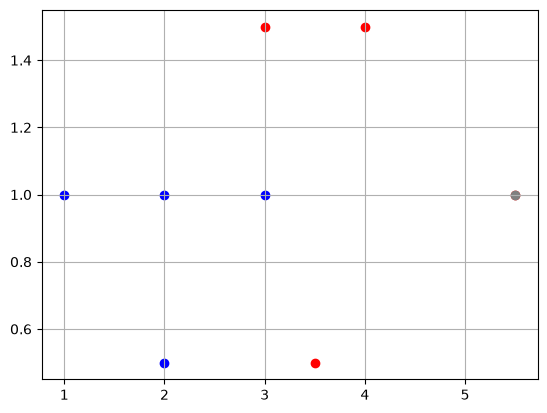

In [31]:
# scatter plot them
def vis_data():
    plt.grid()

    for i in range(len(data)):
        c = 'r'
        if data[i][2] == 0:
            c = 'b'
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

In [32]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [33]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

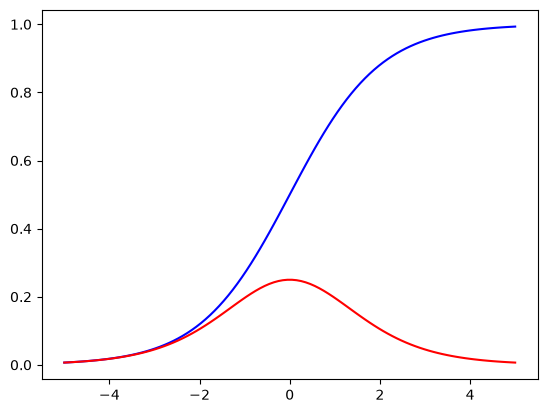

In [ ]:
X = np.linspace(-5, 5, 100)


plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red

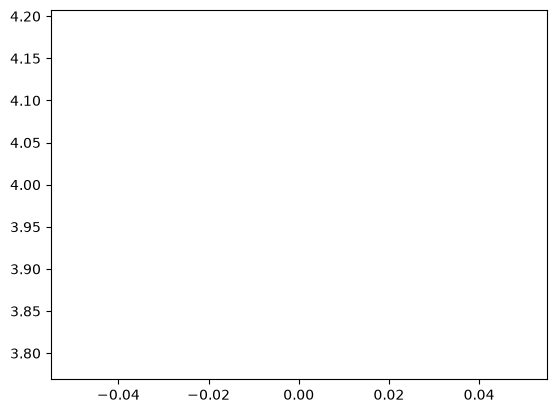

In [ ]:
# train

def train():
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()
    
    iterations = 100
    learning_rate = 0.00001
    costs = [] # keep costs during training, see if they go down
    
    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]
        
        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction
        
        target = point[2]
        
        # cost for current random point
        # cost = np.square(pred - target)
        cost = (pred - target)
        
        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)
        
        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)
        
        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1
        
        dcost_dz = dcost_dpred * dpred_dz
        
        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db
        
        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db
        
    return costs, w1, w2, b
        
costs, w1, w2, b = train()

fig = plt.plot(costs)

In [28]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.00023608388299028573
close to 0 -> blue, close to 1 -> red


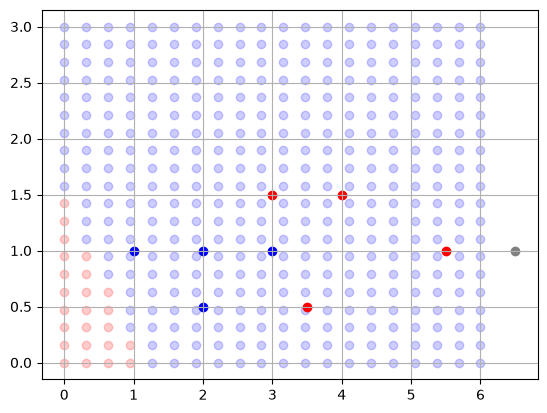

In [29]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)
        
# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()

## Word to Vec implementation
